# Multi-LoRA email workshop: data and routing

**Primary question:** Can a text-only router select finance, travel, and general operations specialists without consulting the email's true labels?

This notebook follows the CLM notebook pattern: evaluation contract, secure configuration, fail-fast data checks, a small baseline, charts, and reproducibility artifacts.

**Time:** 45-60 minutes. **Hardware:** CPU. Run cells top to bottom. Data lineage and routing are model-independent; the model-profile choice intentionally starts in notebook 02. See the [workshop guide](../README.md) for setup and the complete agenda.

## Evaluation contract

- The source is **multi-label**, despite its repository name: preserve every label, including `Business` + `Reminders`.
- Pin the dataset revision; validate subject/body/labels before splitting.
- Collapse normalized exact duplicates with identical labels; quarantine conflicting duplicates and record their IDs.
- Make an iterative multi-label 70/15/15 split. Fit vocabulary and classifiers on **train only**; tune thresholds on **validation only**.
- Never route using ground-truth labels. Keep the test split sealed until the final comparison.
- This CPU baseline is a real TF-IDF classifier, **not** LoRA training, an LLM, or a proxy for GPU quality.

In [1]:
from __future__ import annotations

import json
import os
import platform
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import email_workshop
from email_workshop.data import DOMAINS, LABELS, label_matrix, load_splits, prepare, write_json
from email_workshop.evaluation import lexical_predictions, score
from email_workshop.routing import fit_router

WORKSHOP_ROOT = Path(email_workshop.__file__).resolve().parents[1]
ARTIFACT_DIR = WORKSHOP_ROOT / Path(os.getenv('EMAIL_WORKSHOP_RUN', 'artifacts/run-2026'))
RANDOM_STATE = 2026
TARGET_ROUTING_RECALL = 0.95
RUN_PREPARATION = True
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Python: {platform.python_version()} | Kernel: {sys.executable}')
print(f'Artifacts: {ARTIFACT_DIR}')

h:\masterswork\gitrash\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.10 | Kernel: h:\masterswork\gitrash\.venv\Scripts\python.exe
Artifacts: H:\masterswork\gitrash\multi-lora\workshops\email-multilora\artifacts\run-2026


## Secure configuration

The dataset and small base model are public; no token is required. Hugging Face can use `HF_TOKEN` if your environment requires it. Never print the token. This notebook downloads public data but does not upload emails or models.

Artifacts and `.env` files are ignored by Git. The raw data lives in the local Hugging Face cache; split files contain email text and should stay local. The publisher labels the dataset MIT, but that alone does not establish that every email is synthetic or PII-free.

In [2]:
if (ARTIFACT_DIR / 'data' / 'manifest.json').exists():
    splits, manifest = load_splits(ARTIFACT_DIR)
    print('Reusing verified immutable splits.')
elif RUN_PREPARATION:
    manifest = prepare(ARTIFACT_DIR, seed=RANDOM_STATE)
    splits, manifest = load_splits(ARTIFACT_DIR)
else:
    raise FileNotFoundError('Run preparation once or select an existing EMAIL_WORKSHOP_RUN.')

display(pd.Series({key: manifest[key] for key in ['raw_rows', 'unique_rows', 'rows_removed', 'dataset_revision']}))
display(pd.DataFrame({name: item['label_counts'] for name, item in manifest['splits'].items()}).reindex(LABELS))
print('Quarantine audit:', manifest['deduplication'])

Reusing verified immutable splits.


raw_rows                                                2105
unique_rows                                             2103
rows_removed                                               2
dataset_revision    e95090f0bb6dae0b05c9cd6db314dcae1d40db3f
dtype: object

,train,validation,test
Business,657,141,141
Customer Support,159,34,34
Events & Invitations,458,99,98
Finance & Bills,234,50,50
Job Application,85,19,18
Newsletters,139,30,30
Personal,155,33,33
Promotions,84,18,18
Reminders,239,51,51
Travel & Bookings,220,47,47


Quarantine audit: {'repeated_text_rows': 1, 'conflicting_groups': {'7898a49b604fa90127ac4d1a232a829626abdbbd08400b80e9823b54ea0850eb': [['Business', 'Events & Invitations', 'Reminders'], ['Business', 'Reminders']]}, 'conflicting_texts_removed': 1, 'policy': 'collapse same-label exact duplicates; exclude all conflicting text groups'}


## Optional local CSV export

The next cell exports every **usable prepared email** from the pinned Hugging Face source into one local CSV. It includes the deterministic row ID, assigned split, subject, body, JSON-encoded labels, label count, dataset ID, and dataset revision.

The export contains 2,103 rows rather than the 2,105 raw rows because the two conflicting duplicate rows were deliberately quarantined during preparation. The CSV includes the sealed test email text and labels, so use it for inspection or controlled downstream analysis—not for feature fitting, threshold selection, prompt tuning, or repeated test-set experimentation.

The destination is `data/email_dataset.csv`, relative to the workshop root. The entire `data/` directory is ignored by Git because it contains email text.

In [ ]:
CSV_PATH = WORKSHOP_ROOT / 'data' / 'email_dataset.csv'
export_rows = [
    {
        'id': row['id'],
        'split': split_name,
        'subject': row['subject'],
        'body': row['body'],
        'labels_json': json.dumps(row['labels'], ensure_ascii=False),
        'label_count': len(row['labels']),
        'dataset': manifest['dataset'],
        'dataset_revision': manifest['dataset_revision'],
    }
    for split_name in ('train', 'validation', 'test')
    for row in splits[split_name]
]
export_frame = pd.DataFrame(export_rows)
expected_rows = sum(len(rows) for rows in splits.values())
if len(export_frame) != expected_rows or export_frame['id'].nunique() != expected_rows:
    raise ValueError('CSV export must contain every prepared email exactly once.')
CSV_PATH.parent.mkdir(parents=True, exist_ok=True)
temporary_csv = CSV_PATH.with_suffix('.csv.tmp')
export_frame.to_csv(temporary_csv, index=False, encoding='utf-8')
temporary_csv.replace(CSV_PATH)
print(f'Exported {len(export_frame):,} usable emails to {CSV_PATH.relative_to(WORKSHOP_ROOT)}')
display(export_frame.groupby('split', sort=False).size().rename('rows'))

## Inspect imbalance and overlapping labels

At the pinned revision, the source has 2,105 rows. One text appears twice with conflicting labels, so the preparation policy retains 2,103 usable emails. With seed 2026, the expected counts are 1,473 train, 312 validation, and 318 test. Iterative stratification prioritizes label proportions, so sizes need not equal exact rounded percentages.

Only training emails are used below. Subject/body contents are deliberately not displayed.

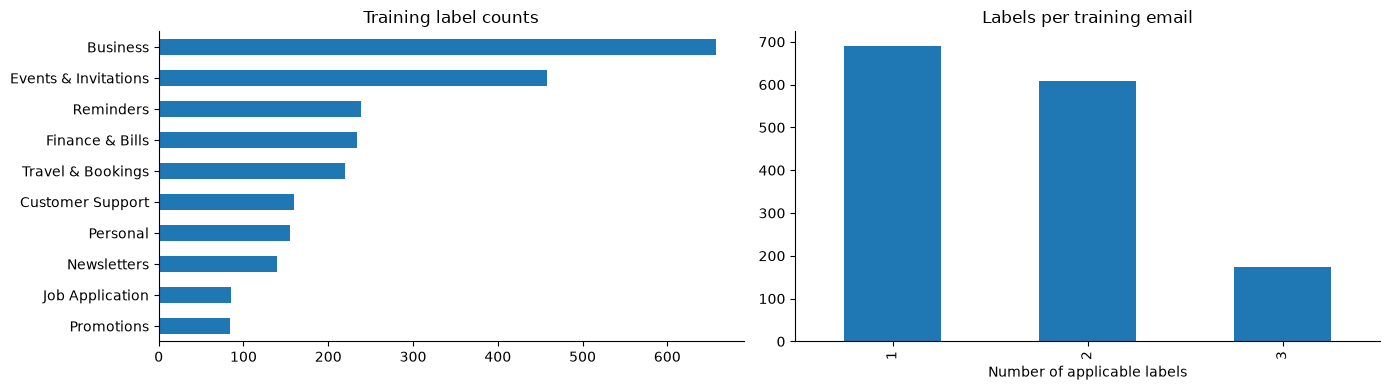

,Business,Customer Support,Events & Invitations,Finance & Bills,Job Application,Newsletters,Personal,Promotions,Reminders,Travel & Bookings
Business,657,125,398,46,0,24,2,1,228,0
Customer Support,125,159,8,54,2,4,0,1,10,9
Events & Invitations,398,8,458,0,0,20,2,0,101,0
Finance & Bills,46,54,0,234,0,0,9,0,3,7
Job Application,0,2,0,0,85,0,9,0,1,0
Newsletters,24,4,20,0,0,139,37,7,0,0
Personal,2,0,2,9,9,37,155,6,0,15
Promotions,1,1,0,0,0,7,6,84,0,1
Reminders,228,10,101,3,1,0,0,0,239,1
Travel & Bookings,0,9,0,7,0,0,15,1,1,220


In [3]:
train_targets = label_matrix(splits['train'])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.Series(train_targets.sum(axis=0), index=LABELS).sort_values().plot.barh(ax=axes[0], title='Training label counts')
pd.Series(train_targets.sum(axis=1)).value_counts().sort_index().plot.bar(ax=axes[1], title='Labels per training email')
axes[1].set_xlabel('Number of applicable labels')
plt.tight_layout()
plt.show()
cooccurrence = pd.DataFrame(train_targets.T @ train_targets, index=LABELS, columns=LABELS)
display(cooccurrence)

### How to read the two dimensions of the co-occurrence matrix

Both dimensions represent the **same label vocabulary**, not actual versus predicted classes:

- **Rows:** choose a label already attached to a training email.
- **Columns:** count how often a second label is attached to those same emails.

Therefore, cell `(row A, column B)` is the number of training emails containing **both** label A and label B. The matrix is symmetric because `A + B` is the same co-occurrence as `B + A`.

The **diagonal** is different: it is each label's total training support. For example, `Business -> Business = 657` means 657 training emails have the Business label. An **off-diagonal** value such as `Business -> Events & Invitations = 398` means 398 emails have both labels; `Business -> Reminders = 228` means 228 have both Business and Reminders. A zero means that pair never occurs in the training split.

This is a label co-occurrence table, **not a confusion matrix** and not model output. It demonstrates why the task is multi-label: many emails legitimately occupy several row/column categories at once. Large raw counts are influenced by label frequency, so compare proportions or normalized co-occurrence—not only counts—when judging association strength.

For the adapter design, cross-domain cells matter. For example, `Finance & Bills -> Travel & Bookings = 7` shows that some emails need both finance and travel predictions. The router must be able to select both specialists, and their validated label arrays are combined by set union rather than forcing one top-1 class.

## Define the adapter contracts

A LoRA adapter contract is the explicit agreement between the data, prompt, training target, router, model output, and evaluator. It answers five questions before training begins:

1. **Vocabulary:** Which labels may this adapter return?
2. **Training population:** Which emails does it see? In this workshop, every adapter sees the complete training partition.
3. **Target transformation:** How are the original multi-label targets converted for this adapter?
4. **Invocation:** When is the adapter called at inference time?
5. **Combination and evaluation:** How are its predictions validated, combined, and scored?

The contract is more than a convenient adapter name. It prevents training one behavior while routing or evaluating as if the adapter learned a different behavior.

### Contracts used in this workshop

| Adapter | Allowed output vocabulary | Training target for each email | Inference role |
|---|---|---|---|
| **Generalist** | All ten labels | Keep every ground-truth label | One-call baseline that can classify the entire inbox |
| **Operations** | Business, Customer Support, Events & Invitations, Job Application, Newsletters, Personal, Promotions, Reminders | Intersect the email's labels with the eight operations labels | Handle broad non-finance/non-travel inbox work |
| **Finance** | Finance & Bills | Return `["Finance & Bills"]` when present; otherwise `[]` | Independently detect financial correspondence |
| **Travel** | Travel & Bookings | Return `["Travel & Bookings"]` when present; otherwise `[]` | Independently detect travel correspondence |

Every response must be a JSON array containing only labels allowed by that adapter. The adapter does not invent workflow actions, urgency, reply text, invoice fields, refund decisions, or booking changes.

### Example 1: one email activates two specialists

Suppose an email says:

> **Subject:** Flight invoice available  
> **Body:** Your flight is confirmed. The invoice is due Friday.

Its original labels are:

```json
["Finance & Bills", "Travel & Bookings"]
```

The adapter-specific targets are:

```text
generalist  -> ["Finance & Bills", "Travel & Bookings"]
operations  -> []
finance     -> ["Finance & Bills"]
travel      -> ["Travel & Bookings"]
```

At inference time the router may select both finance and travel. Their validated arrays are combined by set union. This is **domain fan-out**, not forced top-1 classification.

### Example 2: an operations email is a negative example for other specialists

> **Subject:** Project review tomorrow  
> **Body:** Please attend the business review and remember to bring the report.

Original labels:

```json
["Business", "Reminders"]
```

Adapter targets:

```text
generalist  -> ["Business", "Reminders"]
operations  -> ["Business", "Reminders"]
finance     -> []
travel      -> []
```

The empty finance and travel targets are essential supervision. They teach those specialists to remain silent for off-domain email.

### Why train each specialist on the full partition?

A tempting shortcut is to train the finance adapter only on emails already labeled `Finance & Bills`. That creates a positive-only dataset. The adapter may learn that every input deserves the finance label because it never sees counterexamples.

Using the full partition turns specialist training into a real binary or restricted multi-label decision:

```text
Relevant email     -> domain label(s)
Off-domain email   -> []
```

It also makes routing errors measurable. If the router incorrectly sends a newsletter to finance, the finance adapter has been trained to return `[]` rather than producing a guaranteed false positive.

### Why might a data scientist build domain adapters?

#### 1. Different domains change at different rates

Travel language may change when airlines, booking systems, or itinerary formats change. Finance language may change when billing vendors or invoice templates change. Separate adapters allow one domain to be retrained without deliberately modifying every other domain's adapter.

#### 2. Domain teams may own different labels and review processes

A finance team may curate and approve financial examples while an operations team owns support and event labels. Adapter boundaries can mirror data stewardship, annotation expertise, release approval, and audit ownership.

#### 3. Rare domains can receive focused experimentation

A single model may optimize aggregate loss around common labels. A specialist gives the data scientist a controlled place to test sampling, loss weighting, synthetic examples, or domain-specific prompts without changing the generalist experiment. This workshop keeps hyperparameters equal for a fair first comparison; later experiments can document intentional differences.

#### 4. Deployment may avoid unnecessary calls

If most emails are ordinary operations mail, a router can skip finance and travel for most rows. The experiment therefore reports both quality and mean model calls. Specialization is useful only if its quality, governance, or lifecycle benefits justify routing errors and extra operational complexity.

#### 5. Failures become easier to attribute

The system can distinguish:

- **Router failure:** the required specialist was never called.
- **Adapter failure:** the specialist was called but predicted incorrectly.
- **Format failure:** the model did not return valid contract JSON.

This decomposition helps a data scientist decide whether to improve data, routing thresholds, prompts, adapter training, or serving controls.

### Why keep a generalist?

The generalist is the essential control condition. Without it, three specialists receive roughly three adapter-training budgets and potentially three inference calls, so an apparent gain might come from additional compute rather than useful specialization.

A specialist architecture should be adopted only when it beats or operationally justifies itself against the one-call generalist on the same email IDs. In the completed local Nemotron validation run, the generalist was stronger than both specialist strategies, which is a valid and important experimental result.

### What the contract does not guarantee

A contract defines intended behavior; it does not prove that the adapter learned it. The workshop still measures per-label precision/recall, invalid output, routing coverage, exact match, call count, and latency. Domain adapters also add lifecycle costs: more artifacts, more manifests, more routing logic, and more combinations to validate.

In [5]:
domain_table = []
for name, labels in DOMAINS.items():
    positives = sum(bool(set(row['labels']) & set(labels)) for row in splits['train'])
    domain_table.append({'adapter': name, 'allowed_labels': ', '.join(labels), 'positive_rows': positives, 'negative_rows': len(splits['train']) - positives})
display(pd.DataFrame(domain_table))

,adapter,allowed_labels,positive_rows,negative_rows
0,operations,"Business, Customer Support, Events & Invitatio...",1127,346
1,finance,Finance & Bills,234,1239
2,travel,Travel & Bookings,220,1253


## Fit the text-only router and tune on validation

**Learning goal:** Understand how a small, inexpensive classifier chooses which specialist adapters should read an email. Think of the router as an inbox receptionist: it sends a message to finance, travel, operations, or more than one team. The specialists make the final label predictions later.

**Text-only** means that routing uses only the email's **subject and body**. True labels supervise training and measure validation results, but they are never inputs when routing a new email. This section trains a CPU classifier, not an LLM or a LoRA adapter.

### 1. Turn words into numbers with TF-IDF

A classifier cannot directly multiply words, so **TF-IDF** (term frequency-inverse document frequency) converts each email into numeric features. Words that are common in one email but less common across the training emails receive more weight than words that appear almost everywhere.

- **Unigrams** are individual words, such as `invoice` or `flight`.
- **Bigrams** are adjacent two-word phrases, such as `payment due` or `flight confirmation`.
- The vectorizer learns its vocabulary and word statistics from **train only**. Validation and test emails are transformed using that existing vocabulary; they do not teach it new words.

### 2. Learn ten independent yes/no label decisions

**One-vs-rest logistic regression** trains one small classifier per label. Each asks a question such as "Does this email belong to Finance & Bills?" and produces a probability estimate from 0 to 1.

The estimates **do not have to sum to 1**: an email can be both a booking confirmation and a bill. This is why we do not force a single winning label. Training uses balanced class weights to give rarer positive labels more influence, but that does not guarantee accurate or calibrated probabilities.

### 3. Keep the two thresholds separate

A **threshold** is the cutoff a score must meet. This notebook chooses two cutoffs for different jobs:

| Setting | Question it answers | How validation selects it |
|---|---|---|
| `label_threshold` | Which of the ten labels should the **lexical baseline** predict? | Try 0.10 to 0.90 in steps of 0.05 and keep the best micro-F1. |
| `route_threshold` | Which **specialist adapters** should be called? | Try 0.00 to 0.95 in steps of 0.05; keep the fewest average calls that meet `TARGET_ROUTING_RECALL`. |

**Micro-F1** combines precision (how often predicted labels are correct) and recall (how many true labels are found), pooling decisions across all emails and labels. It selects the baseline's cutoff, **not** the routing cutoff. Routing uses the underlying scores directly; a label does not have to pass `label_threshold` before its domain can be selected.

### 4. Convert label scores into three domain scores

The router assigns each domain the **maximum** score among its labels:

- `finance`: the score for Finance & Bills.
- `travel`: the score for Travel & Bookings.
- `operations`: the highest score among its eight labels.

It selects **every domain whose score is greater than or equal to `route_threshold`**. If none passes, it selects the highest-scoring domain anyway. This fallback guarantees at least one specialist call, not a correct route. The generalist adapter is a separate comparison baseline; this router does not select it.

**Worked example (invented scores, not measured results):** An email says, "Your flight is confirmed; the invoice is attached."

| Domain | Illustrative score | Selected at cutoff 0.50? | Selected at cutoff 0.80? |
|---|---:|---|---|
| operations | 0.30 | No | No |
| finance | 0.72 | Yes | No |
| travel | 0.86 | Yes | Yes |

At 0.50, finance and travel both run. At 0.80, only travel runs: one call is saved, but the finance label cannot be recovered by the travel specialist, whose output vocabulary does not include it.

> **Score caution:** A maximum is a routing heuristic, not a calibrated probability that *any* label in the domain is true. Taking the maximum of eight operations scores also differs from using the single finance or travel score. Do not interpret 0.80 as an 80% guarantee of correct routing.

### 5. Tune the recall-versus-calls trade-off on validation

**Domain recall** measures how many relevant email-domain pairs were selected:

`domain recall = relevant email-domain pairs selected / all relevant email-domain pairs`

An email labeled Finance & Bills and Travel & Bookings contributes **two** relevant pairs. If the router selects travel only, it recovers one of those two. Multiple true operations labels on one email still contribute only **one operations pair**.

`TARGET_ROUTING_RECALL = 0.95` asks validation tuning to retain at least 95% of the relevant pairs **in aggregate**. It is not 95% final classification accuracy, a separate 95% guarantee for each domain, or a promise about test data. Check `validation_recall_by_domain`, especially finance and travel.

A lower cutoff generally calls more specialists and misses fewer domains. A higher cutoff generally saves calls but risks skipping a needed specialist. The helper tests the candidate cutoffs **with the fallback included**, keeps those meeting the recall target, and chooses the one with the fewest average calls. If call counts tie, it prefers the higher cutoff. Calling all three specialists gives full routing coverage, but their predictions can still be wrong.

### 6. Read the output of the next cell

The cell calls `fit_router(...)`, displays its metadata, and plots the candidate cutoffs:

| Output | How to interpret it |
|---|---|
| `label_threshold` | Selected cutoff for the lexical label predictions. |
| `route_threshold` | Selected cutoff for specialist selection. |
| `validation_domain_recall` | Aggregate domain recall at the selected routing cutoff. |
| `validation_recall_by_domain` | Recall for each domain; reveals misses hidden by the aggregate. |
| `validation_mean_calls` | Average specialists selected per email, from 1 to 3. This is not measured latency or dollar cost. |
| Plot | Each point is a candidate cutoff: left means fewer calls, up means higher recall. The dashed line is the recall target. |

The helper saves the selected thresholds, validation trials, data fingerprint, and package versions in `router/metadata.json` under this run's artifact directory. The fitted classifier is recreated from train/validation rather than saved as a pickle.

**Before continuing:** Explain why the flight invoice may need two adapters, why label and routing thresholds can differ, and why good routing recall does not prove good final classification. For an optional experiment, compare recall targets 0.90, 0.95, and 0.99 using validation only and record the call/recall trade-off. Freeze the chosen settings before final test evaluation; **never retune after looking at test results**.

In [ ]:
router, router_metadata = fit_router(ARTIFACT_DIR, target_recall=TARGET_ROUTING_RECALL)
display(pd.Series({key: value for key, value in router_metadata.items() if key != 'trials'}))
trials = pd.DataFrame(router_metadata['trials'])
fig, ax = plt.subplots()
ax.plot(trials['mean_calls'], trials['domain_recall'], marker='o')
ax.axhline(TARGET_ROUTING_RECALL, color='tab:red', linestyle='--', label='Validation target')
ax.set(xlabel='Mean specialist calls per email', ylabel='Domain recall', title='Validation routing trade-off')
ax.legend()
plt.show()

## Measure the lexical baseline on validation

Report exact label-set match, micro/macro F1, Hamming loss, and per-label precision/recall. Multiclass log loss and a ten-way confusion matrix are not appropriate for overlapping labels.

Validation metrics are tuning diagnostics, not final held-out quality. The final notebook evaluates all systems on identical test IDs.

In [ ]:
validation_predictions = lexical_predictions(splits['validation'], router)
summary, per_label = score(validation_predictions)
display(pd.Series(summary))
display(pd.DataFrame(per_label).set_index('label'))
write_json(ARTIFACT_DIR / 'router' / 'validation_metrics.json', {'summary': summary, 'per_label': per_label})

## Synthetic routing smoke test

These are hand-written demonstration emails, not evaluation examples. No training labels are passed to `router.domains`. A wrong route is an observation to diagnose on validation, not something to overwrite with the known answer.

In [ ]:
examples = [
    ('Invoice due', 'Please pay the attached supplier invoice by Friday.'),
    ('Flight confirmation', 'Your flight and hotel reservations are confirmed.'),
    ('Travel receipt', 'Your airline booking is confirmed; the invoice is attached.'),
    ('Team meeting', 'Reminder: please attend tomorrow morning\'s project review.'),
]
display(pd.DataFrame([{'example': subject, 'selected_adapters': router.domains(subject, body)} for subject, body in examples]))

## Reproducibility and handoff

The data manifest includes the source checksum, pinned revision, taxonomy, conflict audit, seed, split hashes, and label counts. The router is refitted deterministically from train/validation instead of loading an unsafe pickle.

**Exit check:** Explain why 2,105 became 2,103; why exact-match accuracy is harder than per-label accuracy; why a travel invoice may need two specialists; and why all-negative finance predictions can appear accurate despite being useless.

Continue to [02: train adapters](02_train_email_adapters.ipynb).

In [ ]:
ledger = pd.DataFrame([
    {'artifact': 'data/manifest.json', 'purpose': 'Dataset lineage and immutable splits'},
    {'artifact': 'router/metadata.json', 'purpose': 'Validation-selected thresholds'},
    {'artifact': 'router/validation_metrics.json', 'purpose': 'Lexical validation baseline'},
])
ledger.to_csv(ARTIFACT_DIR / 'artifact_ledger.csv', index=False)
display(ledger)